# Entrega 1 - Preparação dos dados

Neste Jupyter Notebook vamos importar as imagens que estão organizadas em pastas por critério de diagnóstico que serão usados como label.

## Etapa 1 - Preparação do ambiente

Aqui vamos importar as bibliotecas necessárias para esta etapa, e incluir as funções que serão chamadas ao longo do notebook. 

In [4]:
# Instalando as dependências necessárias (Apple Silicon)
%pip install tensorflow scikit-learn opencv-python tqdm seaborn matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

IMG_SIZE = (224, 224) #apesar das imagens originais não serem quadradas, o modelo MobileNetV2 exige uma entrada quadrada. Redimensionamos para 224x224, que é o tamanho recomendado para esse modelo.
BATCH_SIZE = 32
EPOCHS = 30
NUM_CLASSES = 4
CLASSES = ['anormal', 'hist_inf_mio', 'inf_mio', 'normal']

TRAIN_DIR = os.path.join('assets', 'ECG_DATA', 'treino')
TEST_DIR  = os.path.join('assets', 'ECG_DATA', 'teste')

print(f"TensorFlow versão: {tf.__version__}")
print(f"GPU disponível: {tf.config.list_physical_devices('GPU')}")

TensorFlow versão: 2.21.0
GPU disponível: []


## Etapa 2 - Pré-processamento e Carregamento dos Dados

Aplicamos três técnicas de pré-processamento:
- **Redimensionamento**: todas as imagens são ajustadas para 224×224 pixels
- **Normalização**: valores de pixel escalados para o intervalo [0, 1]
- **Conversão de formato**: leitura em RGB, convertida internamente pelo `ImageDataGenerator`

No conjunto de treino também aplicamos *data augmentation* (translação e zoom) para aumentar a generalização do modelo.

In [6]:
# Gerador para treino: normalização + data augmentation + split 80/20 para validação
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=0,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=False,
    zoom_range=0.1,
    validation_split=0.2
)

# Gerador para teste: apenas normalização
test_datagen = ImageDataGenerator(rescale=1.0 / 255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASSES,
    subset='training',
    shuffle=True,
    seed=42
)

val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASSES,
    subset='validation',
    shuffle=False,
    seed=42
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASSES,
    shuffle=False
)

print(f"Mapeamento de classes: {train_generator.class_indices}")
print(f"Amostras de treino:    {train_generator.samples}")
print(f"Amostras de validação: {val_generator.samples}")
print(f"Amostras de teste:     {test_generator.samples}")

Found 2420 images belonging to 4 classes.
Found 603 images belonging to 4 classes.
Found 928 images belonging to 4 classes.
Mapeamento de classes: {'anormal': 0, 'hist_inf_mio': 1, 'inf_mio': 2, 'normal': 3}
Amostras de treino:    2420
Amostras de validação: 603
Amostras de teste:     928


## Etapa 3 - Visualização de Amostras

Exibimos um exemplo de cada classe antes e depois do pré-processamento.

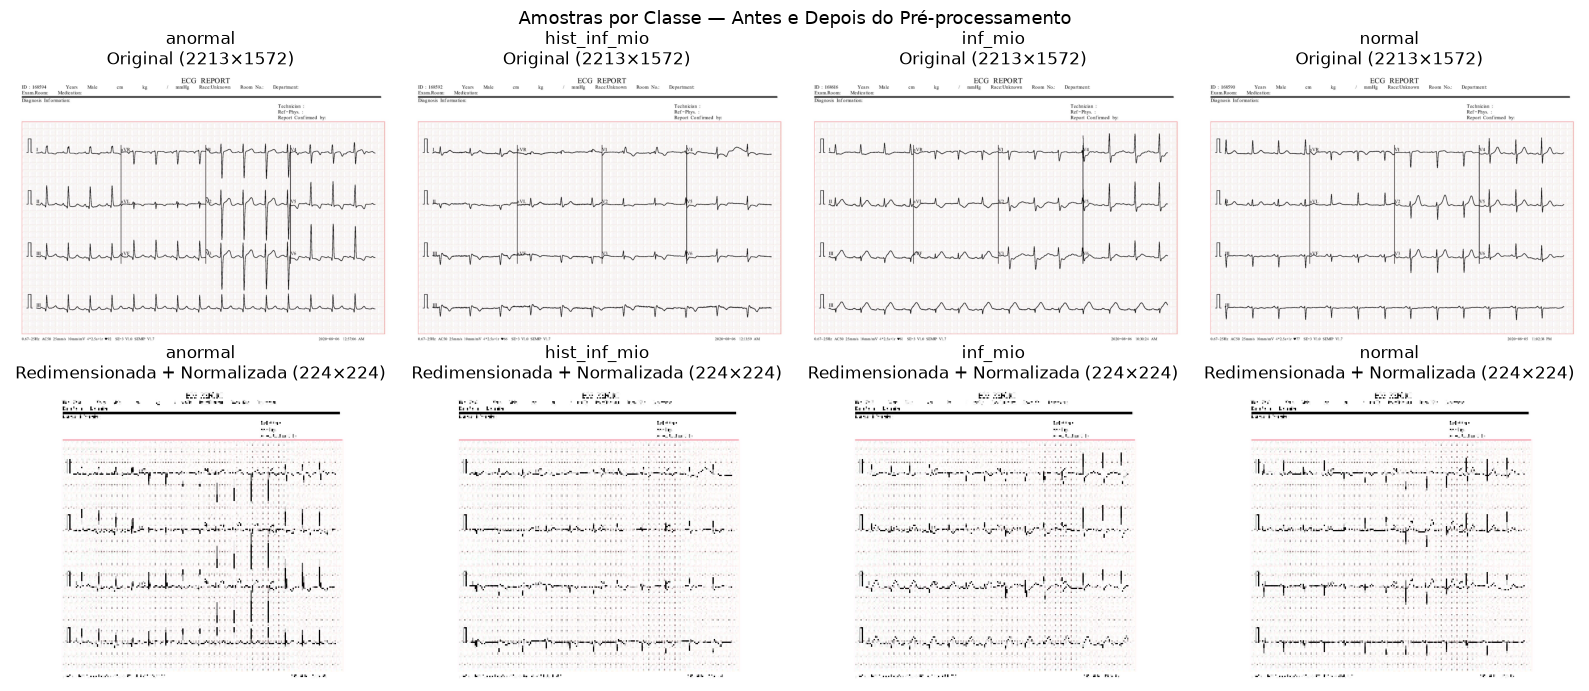

In [7]:
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(16, 7))

for i, cls in enumerate(CLASSES):
    cls_dir = os.path.join(TRAIN_DIR, cls)
    sample_file = next(f for f in os.listdir(cls_dir) if not f.startswith('.'))
    img_bgr = cv2.imread(os.path.join(cls_dir, sample_file))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, IMG_SIZE)

    axes[0, i].imshow(img_rgb)
    axes[0, i].set_title(f'{cls}\nOriginal ({img_rgb.shape[1]}×{img_rgb.shape[0]})')
    axes[0, i].axis('off')

    axes[1, i].imshow(img_resized / 255.0)
    axes[1, i].set_title(f'{cls}\nRedimensionada + Normalizada ({IMG_SIZE[0]}×{IMG_SIZE[1]})')
    axes[1, i].axis('off')

plt.suptitle('Amostras por Classe — Antes e Depois do Pré-processamento', fontsize=13)
plt.tight_layout()
plt.show()

## Etapa 4 - Arquitetura da CNN

Definimos uma CNN com três blocos convolucionais (Conv → BN → Conv → MaxPool → Dropout), seguida de um classificador denso com Dropout. A saída usa `softmax` para as 4 classes.

In [8]:
def build_cnn(input_shape=(224, 224, 3), num_classes=4):
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        # Bloco 1 — 32 filtros
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Bloco 2 — 64 filtros
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Bloco 3 — 128 filtros
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Classificador
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax'),
    ])
    return model

model = build_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,980,324 (99.11 MB)

 Trainable params: 25,979,364 (99.10 MB)

 Non-trainable params: 960 (3.75 KB)

## Etapa 5 - Treinamento

Usamos o otimizador Adam com `EarlyStopping` (paciência 5) e `ReduceLROnPlateau` para evitar overfitting. O melhor modelo é salvo em disco.

In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint('cnn_ecg_model.keras', save_best_only=True, verbose=1),
]

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 802ms/step - accuracy: 0.5021 - loss: 1.2823
Epoch 1: val_loss improved from None to 4.02170, saving model to cnn_ecg_model.keras

Epoch 1: finished saving model to cnn_ecg_model.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 76s 978ms/step - accuracy: 0.5351 - loss: 1.1753 - val_accuracy: 0.2819 - val_loss: 4.0217 - learning_rate: 0.0010
Epoch 2/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 796ms/step - accuracy: 0.6186 - loss: 0.9664
Epoch 2: val_loss did not improve from 4.02170
76/76 ━━━━━━━━━━━━━━━━━━━━ 72s 940ms/step - accuracy: 0.6227 - loss: 0.9320 - val_accuracy: 0.2819 - val_loss: 6.3935 - learning_rate: 0.0010
Epoch 3/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 788ms/step - accuracy: 0.6900 - loss: 0.8009
Epoch 3: val_loss did not improve from 4.02170
76/76 ━━━━━━━━━━━━━━━━━━━━ 71s 933ms/step - accuracy: 0.7174 - loss: 0.7217 - val_accuracy: 0.2819 - val_loss: 4.6555 - learning_rate: 0.0010
Epoch 4/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 787ms/step - accuracy: 0.7715 - loss: 0.5

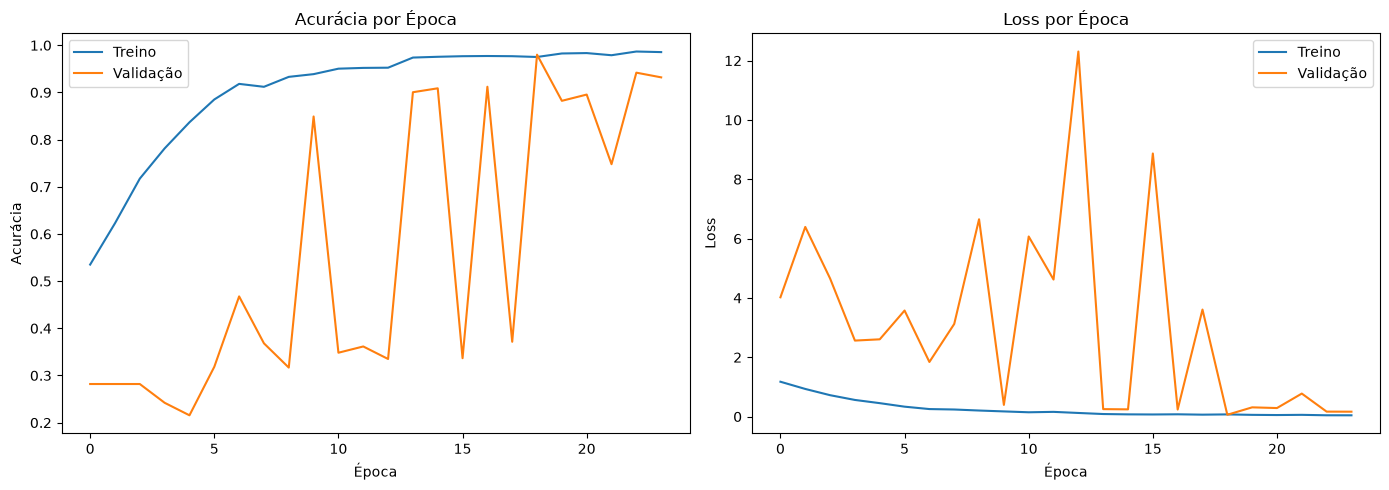

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'],     label='Treino')
axes[0].plot(history.history['val_accuracy'], label='Validação')
axes[0].set_title('Acurácia por Época')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Acurácia')
axes[0].legend()

axes[1].plot(history.history['loss'],     label='Treino')
axes[1].plot(history.history['val_loss'], label='Validação')
axes[1].set_title('Loss por Época')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

## Etapa 6 - Avaliação do Modelo

Avaliamos o modelo no conjunto de teste com acurácia, relatório de classificação por classe e matriz de confusão.

Acurácia no conjunto de teste: 0.9353
Loss no conjunto de teste:     0.1552

29/29 ━━━━━━━━━━━━━━━━━━━━ 11s 385ms/step
Relatório de Classificação:
              precision    recall  f1-score   support

     anormal       1.00      0.82      0.90       233
hist_inf_mio       0.85      1.00      0.92       172
     inf_mio       1.00      0.93      0.97       239
      normal       0.91      0.99      0.95       284

    accuracy                           0.94       928
   macro avg       0.94      0.94      0.93       928
weighted avg       0.94      0.94      0.93       928



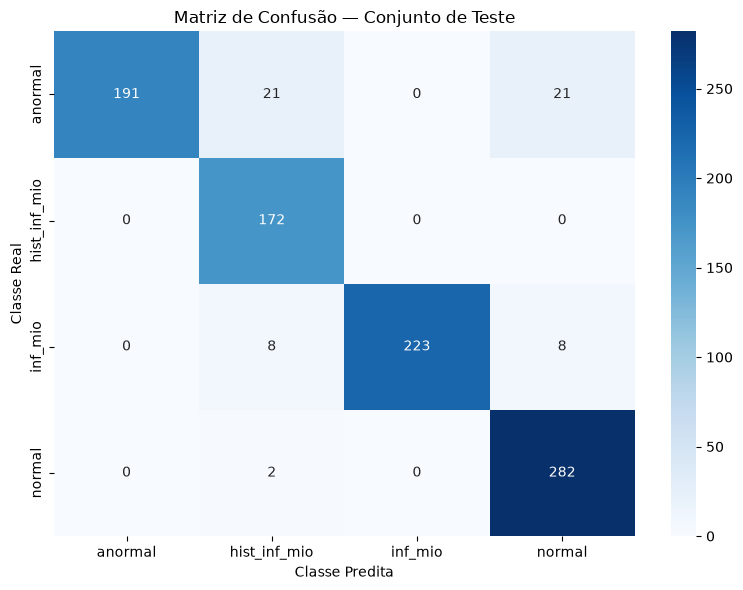

In [12]:
test_loss, test_acc = model.evaluate(test_generator, verbose=0)
print(f"Acurácia no conjunto de teste: {test_acc:.4f}")
print(f"Loss no conjunto de teste:     {test_loss:.4f}\n")

y_pred_probs = model.predict(test_generator)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes

print("Relatório de Classificação:")
print(classification_report(y_true, y_pred, target_names=CLASSES))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Matriz de Confusão — Conjunto de Teste')
plt.ylabel('Classe Real')
plt.xlabel('Classe Predita')
plt.tight_layout()
plt.show()

## Etapa 7 - Transfer Learning com ResNet50

Utilizamos a ResNet50 pré-treinada no ImageNet como extrator de features. A abordagem é feita em duas fases:

1. **Fase 1 — base congelada**: treina apenas o classificador adicionado no topo, mantendo todos os pesos da ResNet50 fixos.
2. **Fase 2 — fine-tuning**: descongela as últimas 20 camadas da ResNet50 e retreina com taxa de aprendizado muito menor para adaptar os features ao domínio de ECG.

O pré-processamento usa `preprocess_input` da própria ResNet50 (subtração de média por canal, escala BGR), que é diferente da normalização simples `÷255` usada na CNN do zero.

In [13]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess

# Geradores com pré-processamento específico da ResNet50 (sem rescale manual)
tl_train_datagen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    validation_split=0.2
)

tl_test_datagen = ImageDataGenerator(preprocessing_function=resnet_preprocess)

tl_train_generator = tl_train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASSES,
    subset='training',
    shuffle=True,
    seed=42
)

tl_val_generator = tl_train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASSES,
    subset='validation',
    shuffle=False,
    seed=42
)

tl_test_generator = tl_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=CLASSES,
    shuffle=False
)

print(f"Amostras de treino (TL):    {tl_train_generator.samples}")
print(f"Amostras de validação (TL): {tl_val_generator.samples}")
print(f"Amostras de teste (TL):     {tl_test_generator.samples}")

Found 2420 images belonging to 4 classes.
Found 603 images belonging to 4 classes.
Found 928 images belonging to 4 classes.
Amostras de treino (TL):    2420
Amostras de validação (TL): 603
Amostras de teste (TL):     928


In [14]:
def build_resnet50(input_shape=(224, 224, 3), num_classes=4):
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False  # Fase 1: base congelada

    inputs = keras.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs)
    return model, base_model

tl_model, tl_base = build_resnet50()
tl_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,308 (91.99 MB)

 Trainable params: 526,084 (2.01 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

## Etapa 8 - Treinamento com Transfer Learning

### Fase 1 — Classificador com base congelada

Treinamos apenas as camadas densas adicionadas, sem alterar os pesos da ResNet50. Usamos LR mais alto pois os pesos aleatórios do classificador precisam convergir rapidamente.

In [15]:
tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

tl_callbacks = [
    keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint('resnet50_ecg_fase1.keras', save_best_only=True, verbose=1),
]

print("=== Fase 1: base congelada ===")
tl_history_f1 = tl_model.fit(
    tl_train_generator,
    validation_data=tl_val_generator,
    epochs=EPOCHS,
    callbacks=tl_callbacks
)

=== Fase 1: base congelada ===
Epoch 1/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 552ms/step - accuracy: 0.4580 - loss: 1.3922
Epoch 1: val_loss improved from None to 1.22005, saving model to resnet50_ecg_fase1.keras

Epoch 1: finished saving model to resnet50_ecg_fase1.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 58s 727ms/step - accuracy: 0.5380 - loss: 1.1914 - val_accuracy: 0.4478 - val_loss: 1.2200 - learning_rate: 0.0010
Epoch 2/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 550ms/step - accuracy: 0.6329 - loss: 0.9500
Epoch 2: val_loss improved from 1.22005 to 0.86386, saving model to resnet50_ecg_fase1.keras

Epoch 2: finished saving model to resnet50_ecg_fase1.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 53s 698ms/step - accuracy: 0.6364 - loss: 0.9211 - val_accuracy: 0.6385 - val_loss: 0.8639 - learning_rate: 0.0010
Epoch 3/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 575ms/step - accuracy: 0.6549 - loss: 0.8743
Epoch 3: val_loss did not improve from 0.86386
76/76 ━━━━━━━━━━━━━━━━━━━━ 55s 730ms/step - accuracy: 0.6533 - loss: 0.8634 -

### Fase 2 — Fine-tuning das últimas camadas

Descongelamos as últimas 20 camadas da ResNet50 e retreinamos com LR 100× menor para adaptar os features de alto nível ao domínio de ECG sem destruir o conhecimento pré-treinado.

=== Fase 2: fine-tuning ===
Epoch 1/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.5635 - loss: 1.1735
Epoch 1: val_loss improved from None to 0.61579, saving model to resnet50_ecg_finetuned.keras

Epoch 1: finished saving model to resnet50_ecg_finetuned.keras
76/76 ━━━━━━━━━━━━━━━━━━━━ 64s 789ms/step - accuracy: 0.5963 - loss: 1.0668 - val_accuracy: 0.7529 - val_loss: 0.6158 - learning_rate: 1.0000e-05
Epoch 2/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 616ms/step - accuracy: 0.6656 - loss: 0.8405
Epoch 2: val_loss did not improve from 0.61579
76/76 ━━━━━━━━━━━━━━━━━━━━ 58s 766ms/step - accuracy: 0.6653 - loss: 0.8534 - val_accuracy: 0.7197 - val_loss: 0.6543 - learning_rate: 1.0000e-05
Epoch 3/30
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 610ms/step - accuracy: 0.7074 - loss: 0.7243
Epoch 3: val_loss did not improve from 0.61579
76/76 ━━━━━━━━━━━━━━━━━━━━ 58s 760ms/step - accuracy: 0.7174 - loss: 0.7219 - val_accuracy: 0.7280 - val_loss: 0.6620 - learning_rate: 1.0000e-05
Epoch 4/30
76/76 ━━━━━━━

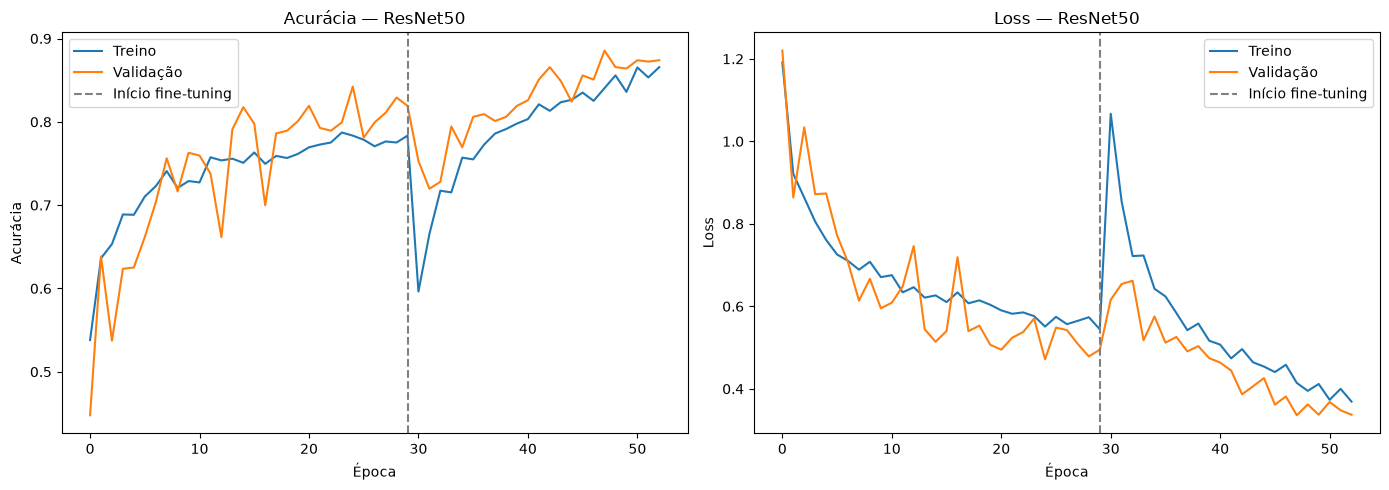

In [16]:
tl_base.trainable = True
for layer in tl_base.layers[:-20]:
    layer.trainable = False

tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

tl_callbacks_ft = [
    keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    keras.callbacks.ModelCheckpoint('resnet50_ecg_finetuned.keras', save_best_only=True, verbose=1),
]

print("=== Fase 2: fine-tuning ===")
tl_history_f2 = tl_model.fit(
    tl_train_generator,
    validation_data=tl_val_generator,
    epochs=EPOCHS,
    callbacks=tl_callbacks_ft
)

# Histórico combinado das duas fases para visualização
phase1_len = len(tl_history_f1.history['accuracy'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ['accuracy', 'loss'], ['Acurácia', 'Loss']):
    combined_train = tl_history_f1.history[metric] + tl_history_f2.history[metric]
    combined_val   = tl_history_f1.history[f'val_{metric}'] + tl_history_f2.history[f'val_{metric}']
    ax.plot(combined_train, label='Treino')
    ax.plot(combined_val,   label='Validação')
    ax.axvline(phase1_len - 1, color='gray', linestyle='--', label='Início fine-tuning')
    ax.set_title(f'{title} — ResNet50')
    ax.set_xlabel('Época')
    ax.set_ylabel(title)
    ax.legend()

plt.tight_layout()
plt.show()

## Etapa 9 - Avaliação do Modelo com Transfer Learning

Avaliamos o modelo ResNet50 fine-tunado no conjunto de teste com as mesmas métricas usadas para a CNN do zero.

Acurácia no conjunto de teste (ResNet50): 0.6789
Loss no conjunto de teste (ResNet50):     0.8094

29/29 ━━━━━━━━━━━━━━━━━━━━ 16s 507ms/step
Relatório de Classificação — ResNet50:
              precision    recall  f1-score   support

     anormal       0.74      0.78      0.76       233
hist_inf_mio       0.52      0.66      0.58       172
     inf_mio       0.65      0.80      0.72       239
      normal       0.85      0.51      0.63       284

    accuracy                           0.68       928
   macro avg       0.69      0.69      0.67       928
weighted avg       0.71      0.68      0.68       928



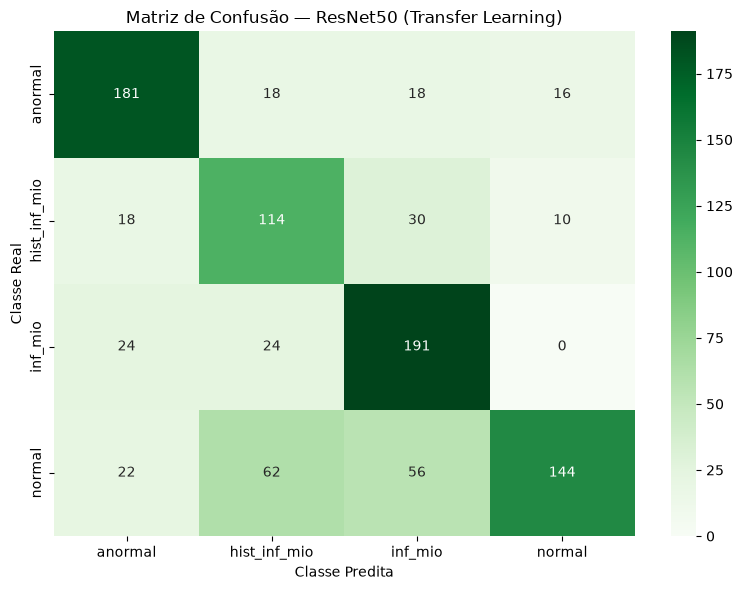

In [17]:
tl_test_loss, tl_test_acc = tl_model.evaluate(tl_test_generator, verbose=0)
print(f"Acurácia no conjunto de teste (ResNet50): {tl_test_acc:.4f}")
print(f"Loss no conjunto de teste (ResNet50):     {tl_test_loss:.4f}\n")

tl_pred_probs = tl_model.predict(tl_test_generator)
tl_pred = np.argmax(tl_pred_probs, axis=1)
tl_true = tl_test_generator.classes

print("Relatório de Classificação — ResNet50:")
print(classification_report(tl_true, tl_pred, target_names=CLASSES))

tl_cm = confusion_matrix(tl_true, tl_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(tl_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Matriz de Confusão — ResNet50 (Transfer Learning)')
plt.ylabel('Classe Real')
plt.xlabel('Classe Predita')
plt.tight_layout()
plt.show()

## Etapa 10 - Comparação dos Modelos

Comparamos lado a lado a CNN treinada do zero com o modelo ResNet50 com transfer learning.

Modelo                 Acurácia       Loss
---------------------------------------------
CNN do Zero              0.9353     0.1552
ResNet50 (TL)            0.6789     0.8094


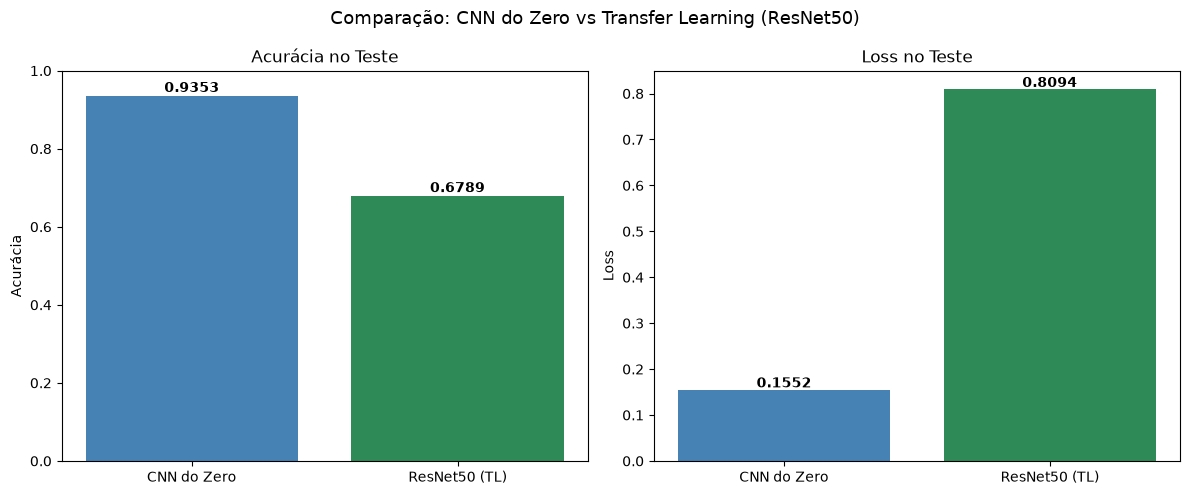

In [18]:
modelos   = ['CNN do Zero', 'ResNet50 (TL)']
acuracias = [test_acc,      tl_test_acc]
losses    = [test_loss,     tl_test_loss]

print("=" * 45)
print(f"{'Modelo':<20} {'Acurácia':>10} {'Loss':>10}")
print("-" * 45)
for nome, acc, loss in zip(modelos, acuracias, losses):
    print(f"{nome:<20} {acc:>10.4f} {loss:>10.4f}")
print("=" * 45)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cores = ['steelblue', 'seagreen']

axes[0].bar(modelos, acuracias, color=cores)
axes[0].set_ylim(0, 1)
axes[0].set_title('Acurácia no Teste')
axes[0].set_ylabel('Acurácia')
for i, v in enumerate(acuracias):
    axes[0].text(i, v + 0.01, f'{v:.4f}', ha='center', fontweight='bold')

axes[1].bar(modelos, losses, color=cores)
axes[1].set_title('Loss no Teste')
axes[1].set_ylabel('Loss')
for i, v in enumerate(losses):
    axes[1].text(i, v + 0.005, f'{v:.4f}', ha='center', fontweight='bold')

plt.suptitle('Comparação: CNN do Zero vs Transfer Learning (ResNet50)', fontsize=13)
plt.tight_layout()
plt.show()